# Forest Proximity Manifold Comparisons

This notebook compares PHATE, UMAP, t-SNE, and Isomap embeddings on `datasets/treeData.csv` using proximity matrices from four forest backends: RandomForest, RotationForest, ObliqueRandomForest, and IsolationForest.

In [ ]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest, RandomForestClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*OOB scores.*", category=UserWarning)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "datasets" / "treeData.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from forestgap import with_sparse_proximity

try:
    from aeon.classification.sklearn import RotationForestClassifier
except ImportError:
    RotationForestClassifier = None

try:
    from treeple import ObliqueRandomForestClassifier
except ImportError:
    ObliqueRandomForestClassifier = None

In [ ]:
data_path = PROJECT_ROOT / "datasets" / "treeData.csv"
tree_data = pd.read_csv(data_path)

X = tree_data.drop(columns="branch")
y = tree_data["branch"].astype(int)

print(f"Loaded {data_path.relative_to(PROJECT_ROOT)}")
print(f"X shape: {X.shape}")
print("Branch counts:")
print(y.value_counts().sort_index().to_string())

Loaded datasets\treeData.csv
X shape: (1440, 60)
Branch counts:
branch
1     180
2     140
3     140
4     140
5     140
6     140
7     140
8     140
9     140
10    140


In [ ]:
backend_specs = [
    {
        "name": "RandomForest",
        "base_cls": RandomForestClassifier,
        "fit_supervised": True,
        "forest_kwargs": {
            "n_estimators": 120,
            "random_state": 42,
            "bootstrap": True,
            "n_jobs": -1,
        },
        "prox_kwargs": {
            "prox_method": "rfgap",
            "matrix_type": "sparse",
            "non_zero_diagonal": True,
        },
    },
    {
        "name": "RotationForest",
        "base_cls": RotationForestClassifier,
        "fit_supervised": True,
        "forest_kwargs": {
            "n_estimators": 80,
            "random_state": 42,
            "n_jobs": -1,
        },
        "prox_kwargs": {
            "prox_method": "rfgap",
            "matrix_type": "sparse",
            "non_zero_diagonal": True,
        },
    },
    {
        "name": "ObliqueRandomForest",
        "base_cls": ObliqueRandomForestClassifier,
        "fit_supervised": True,
        "forest_kwargs": {
            "n_estimators": 120,
            "random_state": 42,
            "bootstrap": True,
            "n_jobs": -1,
        },
        "prox_kwargs": {
            "prox_method": "rfgap",
            "matrix_type": "sparse",
            "non_zero_diagonal": True,
        },
    },
    {
        "name": "IsolationForest",
        "base_cls": IsolationForest,
        "fit_supervised": False,
        "forest_kwargs": {
            "n_estimators": 120,
            "random_state": 42,
            "n_jobs": -1,
        },
        "prox_kwargs": {
            "prox_method": "original",
            "matrix_type": "sparse",
            "non_zero_diagonal": True,
        },
    },
]

backend_specs = [spec for spec in backend_specs if spec["base_cls"] is not None]

embedding_specs = [
    ("PHATE", {"method": "phate", "n_components": 2, "knn": 15, "t": "auto", "n_landmark": 300, "verbose": 0}),
    ("UMAP", {"method": "umap", "n_components": 2, "n_neighbors": 15, "min_dist": 0.1, "symm_mode": "arithmetic"}),
    ("t-SNE", {"method": "tsne", "n_components": 2, "perplexity": 30, "learning_rate": "auto", "max_iter": 750, "symm_mode": "arithmetic"}),
    ("Isomap", {"method": "isomap", "n_components": 2, "n_neighbors": 15, "symm_mode": "arithmetic"}),
]

print("Forest backends:")
for spec in backend_specs:
    print(f"- {spec['name']}")

Forest backends:
- RandomForest
- RotationForest
- ObliqueRandomForest
- IsolationForest


In [ ]:
fitted_forests = {}
all_embeddings = {}

for spec in backend_specs:
    ProxForest = with_sparse_proximity(spec["base_cls"])
    forest = ProxForest(**spec["forest_kwargs"], **spec["prox_kwargs"])

    print(f"Fitting {spec['name']}...")
    if spec["fit_supervised"]:
        forest.fit(X, y)
    else:
        forest.fit(X)

    fitted_forests[spec["name"]] = forest
    all_embeddings[spec["name"]] = {}

    for method_name, method_kwargs in embedding_specs:
        print(f"  {method_name}")
        all_embeddings[spec["name"]][method_name] = forest.embed(**method_kwargs)

summary = {
    backend_name: {method_name: emb.shape for method_name, emb in methods.items()}
    for backend_name, methods in all_embeddings.items()
}
summary

Fitting RandomForest...


  PHATE


    SGD-MDS may not have converged: stress changed by -4.1% in final iterations. Consider increasing n_iter or adjusting learning_rate.


  UMAP


C:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


...

  UMAP


C:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
C:\Users\rhodes8\My Drive\repos\Oblique-RF-PHATE\GeneralForestProximities\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  t-SNE


  Isomap


{'RandomForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'RotationForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'ObliqueRandomForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)},
 'IsolationForest': {'PHATE': (1440, 2),
  'UMAP': (1440, 2),
  't-SNE': (1440, 2),
  'Isomap': (1440, 2)}}

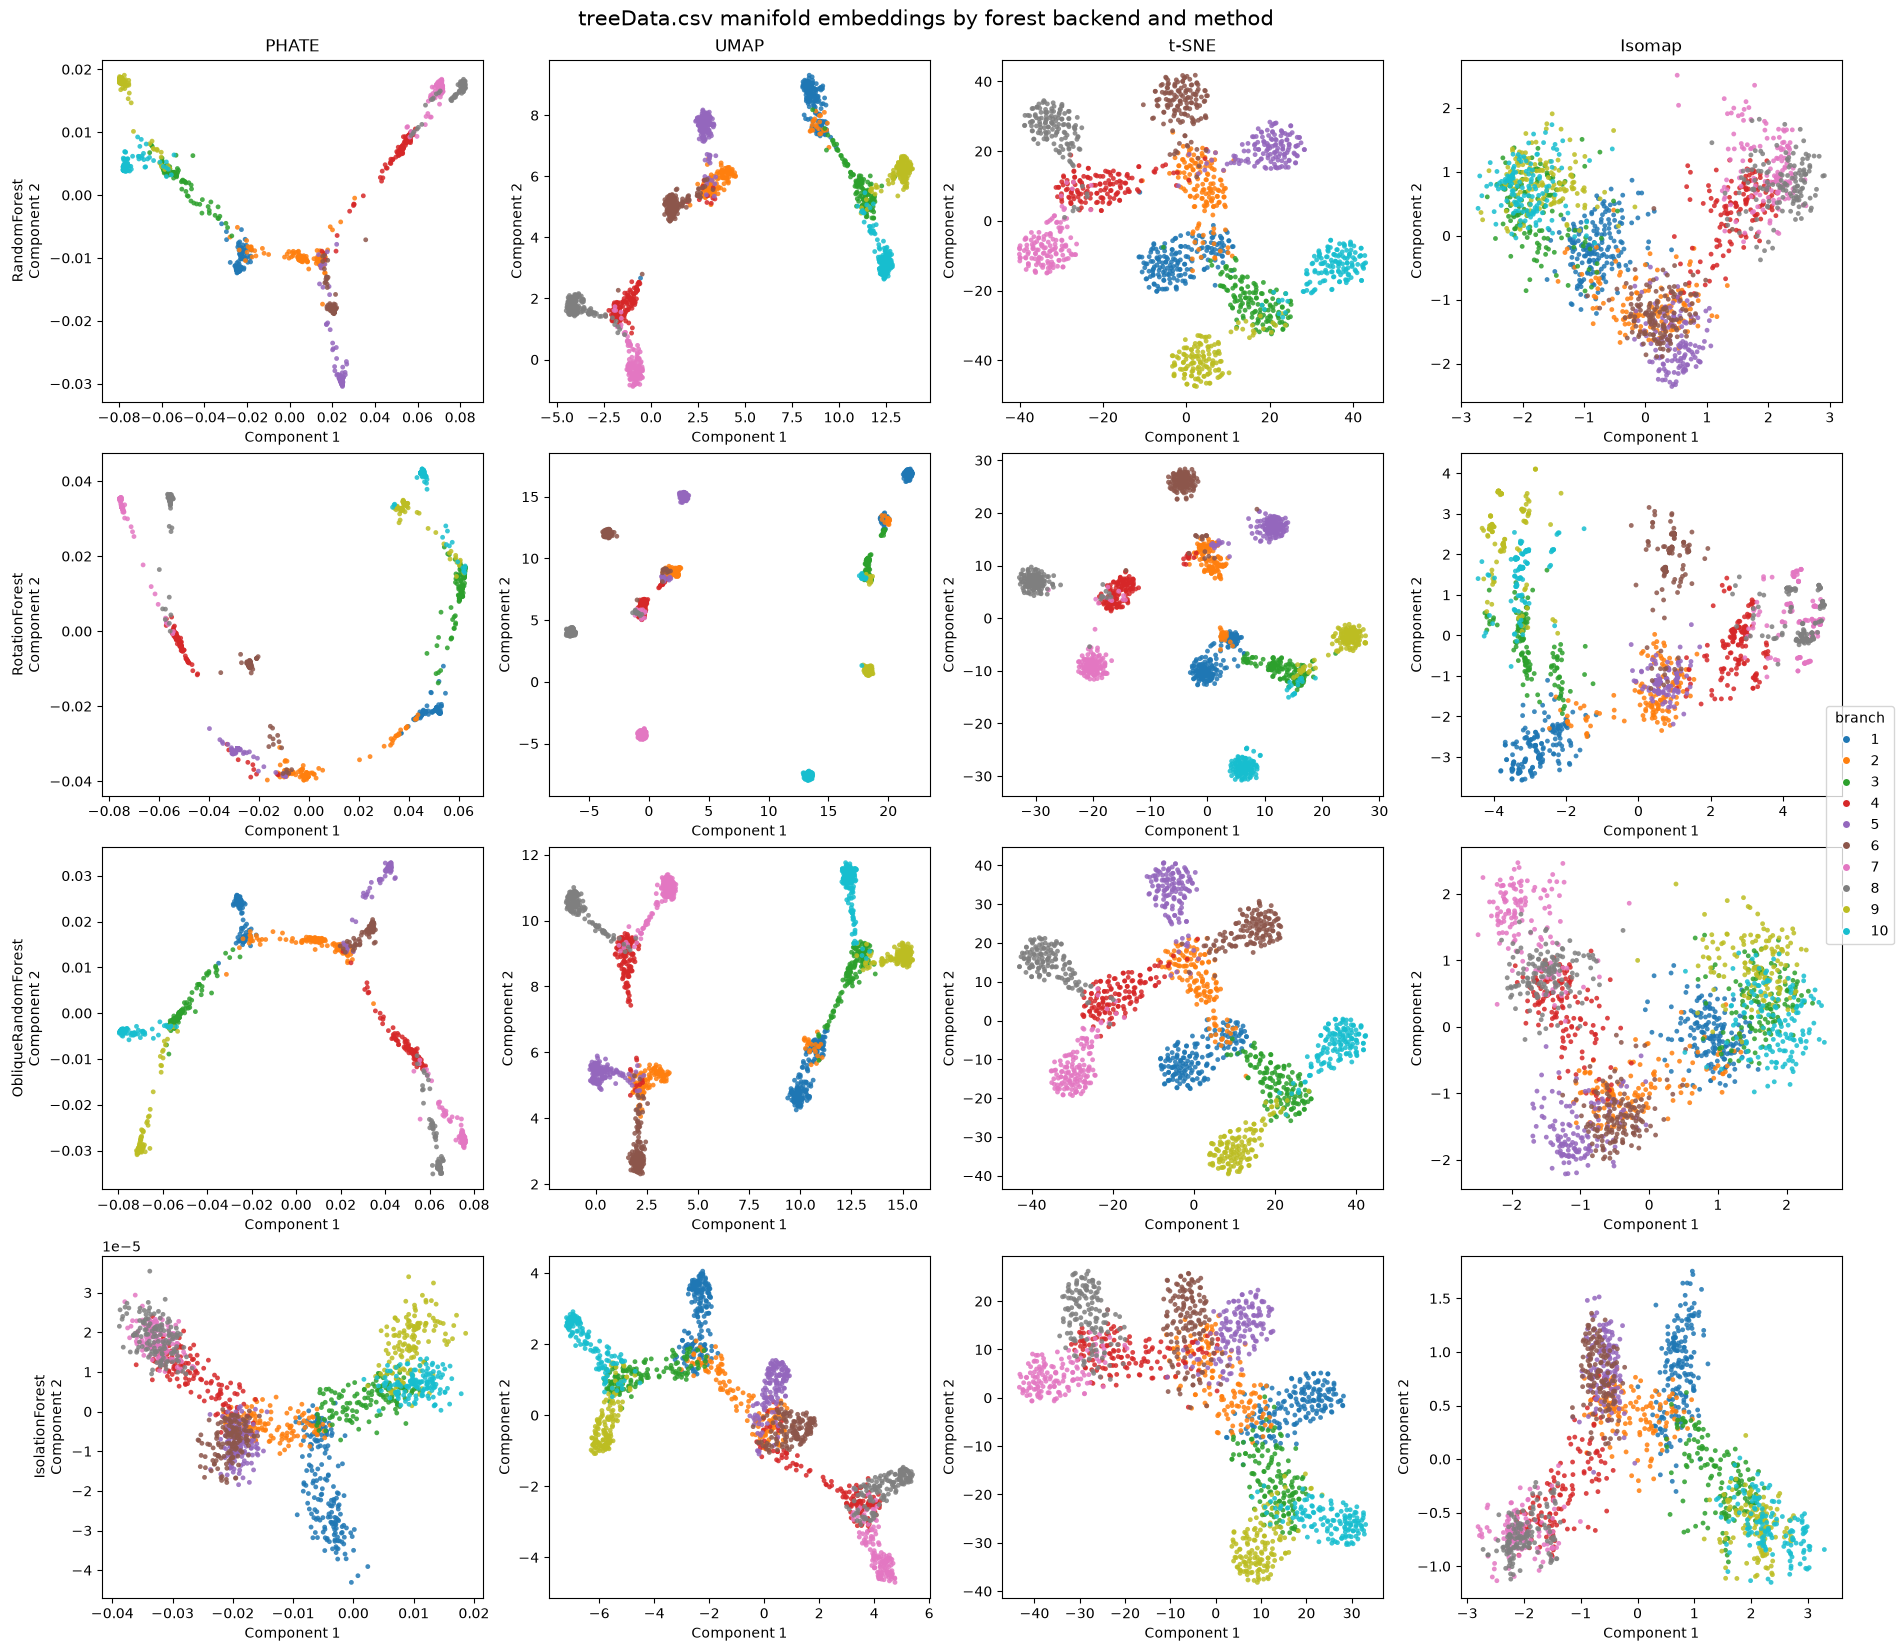

In [ ]:
n_rows = len(backend_specs)
n_cols = len(embedding_specs)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.6 * n_cols, 4.1 * n_rows), constrained_layout=True)

if n_rows == 1:
    axes = np.array([axes])

branches = np.sort(y.unique())
cmap = plt.get_cmap("tab10", len(branches))

for row_idx, spec in enumerate(backend_specs):
    backend_name = spec["name"]
    for col_idx, (method_name, _) in enumerate(embedding_specs):
        ax = axes[row_idx, col_idx]
        emb = all_embeddings[backend_name][method_name]
        ax.scatter(
            emb[:, 0],
            emb[:, 1],
            c=y,
            cmap=cmap,
            s=12,
            alpha=0.85,
            linewidths=0,
        )
        if row_idx == 0:
            ax.set_title(method_name)
        if col_idx == 0:
            ax.set_ylabel(f"{backend_name}\nComponent 2")
        else:
            ax.set_ylabel("Component 2")
        ax.set_xlabel("Component 1")

handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=str(branch),
        markerfacecolor=cmap(i),
        markersize=6,
    )
    for i, branch in enumerate(branches)
]

fig.legend(handles=handles, title="branch", loc="center right", bbox_to_anchor=(1.03, 0.5))
fig.suptitle("treeData.csv manifold embeddings by forest backend and method", fontsize=15)
plt.show()